--- STEP 1: Upload Image File ---
Please select and upload your .jpg or .png image:


Saving 000001.jpg to 000001 (1).jpg
Image uploaded: 000001 (1).jpg

--- STEP 2: Upload JSON File ---
Please select and upload your .json file:


Saving 000001.json to 000001.json
JSON uploaded: 000001.json

Processing files...

Total cracks detected and rendered: 10

Displaying Generated Binary Mask:


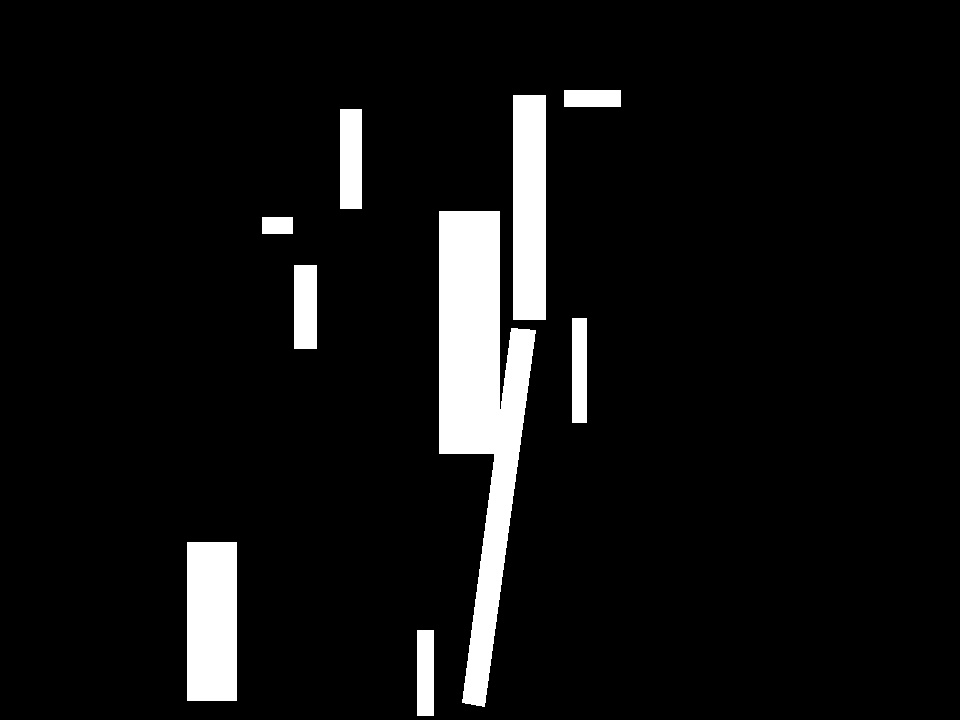

In [ ]:
import os
import json
import cv2
import numpy as np
from google.colab import files
from IPython.display import display, Image

print("--- STEP 1: Upload Image File ---")
print("Please select and upload your .jpg or .png image:")
image_uploaded = files.upload()
image_path = list(image_uploaded.keys())[0]
print(f"Image uploaded: {image_path}\n")

print("--- STEP 2: Upload JSON File ---")
print("Please select and upload your .json file:")
json_uploaded = files.upload()
json_path = list(json_uploaded.keys())[0]
print(f"JSON uploaded: {json_path}\n")

print("Processing files...")

# 1. Load Image and JSON data
img = cv2.imread(image_path)
h, w, _ = img.shape

with open(json_path, 'r') as f:
    data = json.load(f)

# 2. Create a blank binary mask (black background)
binary_mask = np.zeros((h, w), dtype=np.uint8)
crack_count = 0

# 3. Iterate through shapes and draw cracks onto the binary mask
for shape in data.get('shapes', []):
    label = shape.get('label', '')

    # Filter for crack labels
    if 'crack' in label.lower():
        crack_count += 1
        points = shape['points']
        shape_type = shape['shape_type']

        if shape_type == 'polygon':
            pts = np.array(points, dtype=np.int32)
            cv2.fillPoly(binary_mask, [pts], 255)

        elif shape_type == 'rectangle':
            pt1 = (int(points[0][0]), int(points[0][1]))
            pt2 = (int(points[1][0]), int(points[1][1]))
            cv2.rectangle(binary_mask, pt1, pt2, 255, -1)

print(f"\nTotal cracks detected and rendered: {crack_count}")

# 4. Save and display the resulting mask
output_mask_path = 'binary_cracks_mask.jpg'
cv2.imwrite(output_mask_path, binary_mask)

print("\nDisplaying Generated Binary Mask:")
display(Image(output_mask_path))

Identification of standard algorithms and evaluation metrics​

--- Step 1: Upload ALL Image Files (.jpg / .png) ---


Saving 000001.jpg to 000001 (4).jpg

--- Step 2: Upload ALL JSON Files (.json) ---


Saving 000001.json to 000001 (6).json

Successfully verified 1 file pair(s). Processing and displaying...



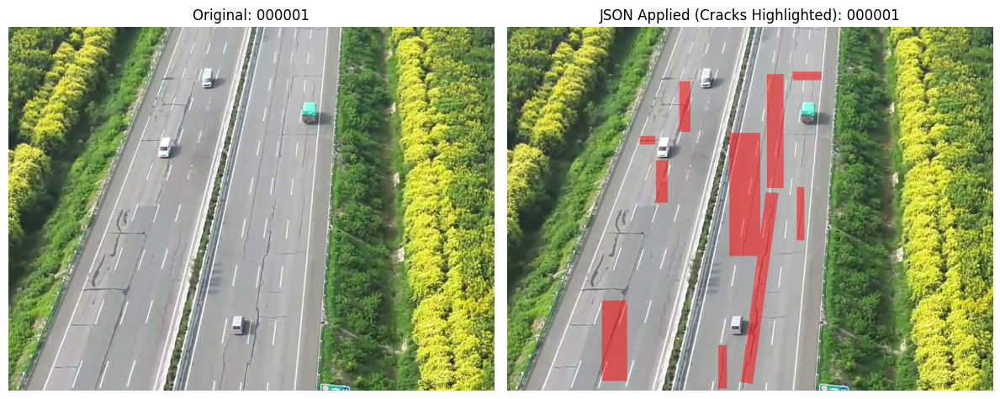

In [ ]:
import os
import re
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("--- Step 1: Upload ALL Image Files (.jpg / .png) ---")
image_uploaded = files.upload()

print("\n--- Step 2: Upload ALL JSON Files (.json) ---")
json_uploaded = files.upload()

def clean_basename(filename):
    """Removes extensions and Google Colab's auto-appended suffixes like ' (1)', ' (3)'."""
    base, _ = os.path.splitext(filename)
    return re.sub(r'\s*\(\d+\)$', '', base).strip()

# Organize uploaded image files by their cleaned base name
image_files = {}
for filename in image_uploaded.keys():
    clean_key = clean_basename(filename)
    image_files[clean_key] = filename

# Organize uploaded JSON files by their cleaned base name
json_files = {}
for filename in json_uploaded.keys():
    clean_key = clean_basename(filename)
    json_files[clean_key] = filename

# Find matching pairs based on the cleaned base names
common_keys = sorted(list(set(image_files.keys()).intersection(set(json_files.keys()))))

# Filter to ensure images can actually be read by OpenCV
valid_pairs = []
for key in common_keys:
    img_path = image_files[key]
    img = cv2.imread(img_path)
    if img is None:
        print(f"Warning: Could not read image file '{img_path}'. Skipping this pair.")
    else:
        valid_pairs.append(key)

if not valid_pairs:
    print("\nError: No valid matching image and JSON pairs could be loaded.")
else:
    print(f"\nSuccessfully verified {len(valid_pairs)} file pair(s). Processing and displaying...\n")

    # Setup plot grid: Each valid pair gets 1 row with 2 columns [Original | Annotated]
    fig, axes = plt.subplots(len(valid_pairs), 2, figsize=(12, 5 * len(valid_pairs)))

    if len(valid_pairs) == 1:
        axes = np.array([axes])

    for i, key in enumerate(valid_pairs):
        img_path = image_files[key]
        js_path = json_files[key]

        # Read image and convert color format for Matplotlib
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        # Read JSON file
        with open(js_path, 'r', encoding='utf-8') as f:
            data = json.load(f)

        # Create overlay copy for drawing crack highlights in red
        overlay = img_rgb.copy()
        for shape in data.get('shapes', []):
            label = shape.get('label', '')
            if 'crack' in label.lower():
                points = shape['points']
                shape_type = shape['shape_type']

                if shape_type == 'polygon':
                    pts = np.array(points, dtype=np.int32)
                    cv2.fillPoly(overlay, [pts], (255, 0, 0)) # Red color
                elif shape_type == 'rectangle':
                    pt1 = (int(points[0][0]), int(points[0][1]))
                    pt2 = (int(points[1][0]), int(points[1][1]))
                    cv2.rectangle(overlay, pt1, pt2, (255, 0, 0), -1)

        # Blend original image and overlay for a clear highlight look
        alpha = 0.5
        annotated_img = cv2.addWeighted(overlay, alpha, img_rgb, 1 - alpha, 0)

        # 1. Display Original Image
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"Original: {key}", fontsize=12)
        axes[i, 0].axis('off')

        # 2. Display Image with JSON Applied
        axes[i, 1].imshow(annotated_img)
        axes[i, 1].set_title(f"JSON Applied (Cracks Highlighted): {key}", fontsize=12)
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

--- Step 1: Upload ALL Image Files (.jpg / .png) ---


Saving 000001.jpg to 000001 (5).jpg

--- Step 2: Upload ALL JSON Files (.json) ---


Saving 000001.json to 000001 (7).json

Found 10 total individual cracks across 1 image(s). Generating individual rows...


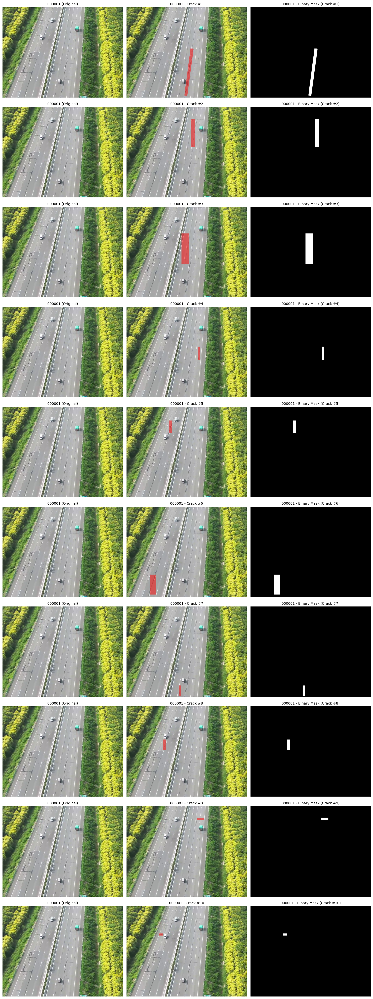

In [ ]:
import os
import re
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("--- Step 1: Upload ALL Image Files (.jpg / .png) ---")
image_uploaded = files.upload()

print("\n--- Step 2: Upload ALL JSON Files (.json) ---")
json_uploaded = files.upload()

def clean_basename(filename):
    """Removes extensions and Google Colab's auto-appended suffixes like ' (1)', ' (3)'."""
    base, _ = os.path.splitext(filename)
    return re.sub(r'\s*\(\d+\)$', '', base).strip()

# Organize uploaded files by their cleaned base name
image_files = {clean_basename(f): f for f in image_uploaded.keys()}
json_files = {clean_basename(f): f for f in json_uploaded.keys()}

common_keys = sorted(list(set(image_files.keys()).intersection(set(json_files.keys()))))

valid_pairs = []
for key in common_keys:
    img_path = image_files[key]
    img = cv2.imread(img_path)
    if img is not None:
        valid_pairs.append(key)

# Build a task list where EACH individual crack gets its own entry
task_list = []
for key in valid_pairs:
    img_path = image_files[key]
    js_path = json_files[key]

    with open(js_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    crack_idx = 0
    for shape in data.get('shapes', []):
        label = shape.get('label', '')
        if 'crack' in label.lower():
            crack_idx += 1
            task_list.append({
                'key': key,
                'img_path': img_path,
                'shape': shape,
                'crack_num': crack_idx
            })

if not task_list:
    print("\nError: No cracks found in the uploaded files.")
else:
    print(f"\nFound {len(task_list)} total individual cracks across {len(valid_pairs)} image(s). Generating individual rows...")

    # Setup plot grid: 1 row per individual crack, with 3 columns [Original | Single Highlight | Single Binary Mask]
    fig, axes = plt.subplots(len(task_list), 3, figsize=(15, 4 * len(task_list)))

    if len(task_list) == 1:
        axes = np.array([axes])

    for i, task in enumerate(task_list):
        key = task['key']
        img_path = task['img_path']
        shape = task['shape']
        crack_num = task['crack_num']

        # Read image
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        # Create overlay and isolated binary mask for THIS specific crack only
        overlay = img_rgb.copy()
        binary_mask = np.zeros((h, w), dtype=np.uint8)

        points = shape['points']
        shape_type = shape['shape_type']

        if shape_type == 'polygon':
            pts = np.array(points, dtype=np.int32)
            cv2.fillPoly(overlay, [pts], (255, 0, 0)) # Red highlight
            cv2.fillPoly(binary_mask, [pts], 255)     # White binary mask for this crack

        elif shape_type == 'rectangle':
            pt1 = (int(points[0][0]), int(points[0][1]))
            pt2 = (int(points[1][0]), int(points[1][1]))
            cv2.rectangle(overlay, pt1, pt2, (255, 0, 0), -1)
            cv2.rectangle(binary_mask, pt1, pt2, 255, -1)

        # Blend image for highlight view
        alpha = 0.5
        annotated_img = cv2.addWeighted(overlay, alpha, img_rgb, 1 - alpha, 0)

        # 1. Column 1: Original Image
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"{key} (Original)", fontsize=10)
        axes[i, 0].axis('off')

        # 2. Column 2: Specific Crack Highlighted
        axes[i, 1].imshow(annotated_img)
        axes[i, 1].set_title(f"{key} - Crack #{crack_num}", fontsize=10)
        axes[i, 1].axis('off')

        # 3. Column 3: Individual Binary Mask for this Crack
        axes[i, 2].imshow(binary_mask, cmap='gray')
        axes[i, 2].set_title(f"{key} - Binary Mask (Crack #{crack_num})", fontsize=10)
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

--- Step 1: Upload ALL Image Files (.jpg / .png) ---


Saving 000001.jpg to 000001 (6).jpg

--- Step 2: Upload ALL JSON Files (.json) ---


Saving 000001.json to 000001 (8).json

Found 10 total individual cracks. Generating individual rows with JSON labels...


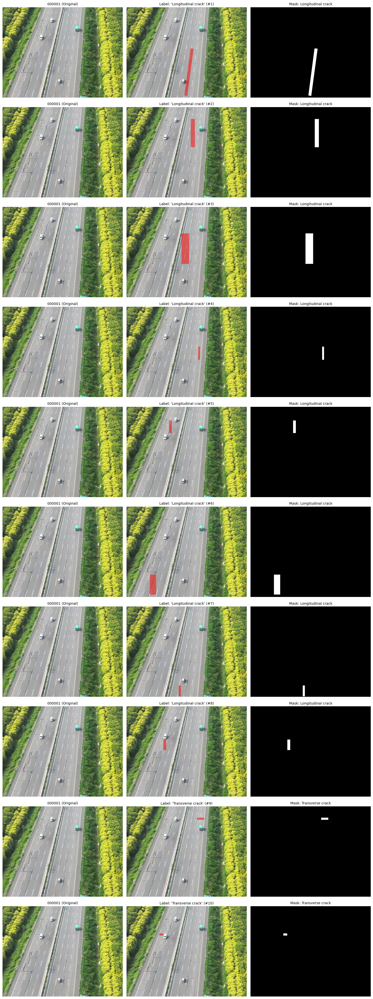

In [ ]:
import os
import re
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("--- Step 1: Upload ALL Image Files (.jpg / .png) ---")
image_uploaded = files.upload()

print("\n--- Step 2: Upload ALL JSON Files (.json) ---")
json_uploaded = files.upload()

def clean_basename(filename):
    """Removes extensions and Google Colab's auto-appended suffixes like ' (1)', ' (3)'."""
    base, _ = os.path.splitext(filename)
    return re.sub(r'\s*\(\d+\)$', '', base).strip()

# Organize uploaded files by their cleaned base name
image_files = {clean_basename(f): f for f in image_uploaded.keys()}
json_files = {clean_basename(f): f for f in json_uploaded.keys()}

common_keys = sorted(list(set(image_files.keys()).intersection(set(json_files.keys()))))

valid_pairs = []
for key in common_keys:
    img_path = image_files[key]
    img = cv2.imread(img_path)
    if img is not None:
        valid_pairs.append(key)

# Build a task list where EACH individual crack gets its own entry with its JSON label
task_list = []
for key in valid_pairs:
    img_path = image_files[key]
    js_path = json_files[key]

    with open(js_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    crack_idx = 0
    for shape in data.get('shapes', []):
        label = shape.get('label', '')
        if 'crack' in label.lower():
            crack_idx += 1
            task_list.append({
                'key': key,
                'img_path': img_path,
                'shape': shape,
                'crack_num': crack_idx,
                'crack_label': label  # Capturing the exact name from the JSON file
            })

if not task_list:
    print("\nError: No cracks found in the uploaded files.")
else:
    print(f"\nFound {len(task_list)} total individual cracks. Generating individual rows with JSON labels...")

    # Setup plot grid: 1 row per individual crack, with 3 columns [Original | Highlight | Binary Mask]
    fig, axes = plt.subplots(len(task_list), 3, figsize=(15, 4 * len(task_list)))

    if len(task_list) == 1:
        axes = np.array([axes])

    for i, task in enumerate(task_list):
        key = task['key']
        img_path = task['img_path']
        shape = task['shape']
        crack_num = task['crack_num']
        crack_label = task['crack_label']

        # Read image
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        # Create overlay and isolated binary mask for THIS specific crack only
        overlay = img_rgb.copy()
        binary_mask = np.zeros((h, w), dtype=np.uint8)

        points = shape['points']
        shape_type = shape['shape_type']

        if shape_type == 'polygon':
            pts = np.array(points, dtype=np.int32)
            cv2.fillPoly(overlay, [pts], (255, 0, 0)) # Red highlight
            cv2.fillPoly(binary_mask, [pts], 255)     # White binary mask for this crack

        elif shape_type == 'rectangle':
            pt1 = (int(points[0][0]), int(points[0][1]))
            pt2 = (int(points[1][0]), int(points[1][1]))
            cv2.rectangle(overlay, pt1, pt2, (255, 0, 0), -1)
            cv2.rectangle(binary_mask, pt1, pt2, 255, -1)

        # Blend image for highlight view
        alpha = 0.5
        annotated_img = cv2.addWeighted(overlay, alpha, img_rgb, 1 - alpha, 0)

        # 1. Column 1: Original Image
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"{key} (Original)", fontsize=10)
        axes[i, 0].axis('off')

        # 2. Column 2: Specific Crack Highlighted with its JSON Label Name
        axes[i, 1].imshow(annotated_img)
        axes[i, 1].set_title(f"Label: '{crack_label}' (#{crack_num})", fontsize=10)
        axes[i, 1].axis('off')

        # 3. Column 3: Individual Binary Mask labeled with its JSON Name
        axes[i, 2].imshow(binary_mask, cmap='gray')
        axes[i, 2].set_title(f"Mask: {crack_label}", fontsize=10)
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()